# Aprendizado Não Supervisionado: Agrupamento

**Aluna:** Layse Steffany Pereira de Souza · UDF · Sistemas de Informação · Ciência de Dados e Aprendizado de Máquina (2026/2)

**Aula:** 28/10 · Unidade IV – Aprendizado de Máquina
**Atividade:** aplicar uma técnica de clustering e interpretar os grupos encontrados.
**Entregável:** análise dos agrupamentos.

O K-Means recebe apenas as características (sem o rótulo). Depois comparamos os grupos com o
rótulo para ver se eles têm significado prático.

In [1]:
import sys
from pathlib import Path

# Permite importar o pacote src/ a partir da pasta do notebook.
# No Google Colab, antes de rodar:
#   !git clone https://github.com/LaySteff/ciencia_dados_aprendizado_maquina.git
#   %cd ciencia_dados_aprendizado_maquina/unidade4_aprendizado_maquina
RAIZ = Path.cwd().resolve().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 30)
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

if config.usando_dados_sinteticos():
    print("AVISO: usando a base SINTÉTICA de demonstração. "
          "Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.")
else:
    print("Usando a amostra real do EMBER.")

AVISO: usando a base SINTÉTICA de demonstração. Os números abaixo são ilustrativos; refaça com a amostra real do EMBER.


In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from src.preparacao import carregar_tratado

df = carregar_tratado()
X = StandardScaler().fit_transform(df[config.FEATURES])

## 1. Escolha do número de grupos (cotovelo e silhueta)

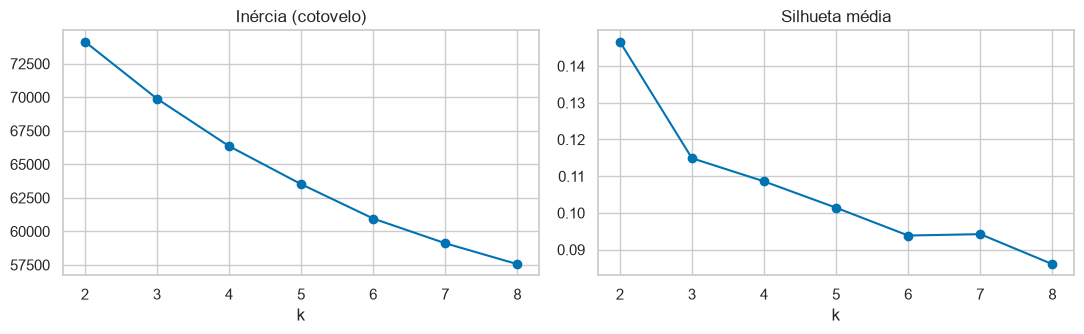

k,2,3,4,5,6,7,8
inércia,74150.000,69896.000,66358.000,63522.000,60957.000,59114.000,57557.000
silhueta,0.147,0.115,0.109,0.101,0.094,0.094,0.086


In [3]:
ks = range(2, 9)
inercia, silh = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inercia.append(km.inertia_)
    silh.append(silhouette_score(X, km.labels_, sample_size=3000, random_state=42))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(ks, inercia, marker="o"); axes[0].set_title("Inércia (cotovelo)"); axes[0].set_xlabel("k")
axes[1].plot(ks, silh, marker="o"); axes[1].set_title("Silhueta média"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inércia": np.round(inercia), "silhueta": np.round(silh, 3)}).set_index("k").T

A silhueta é baixa para todos os k (< 0,15), ou seja, **não há grupos bem separados** nos dados: os arquivos formam um contínuo. A silhueta é um pouco maior em k = 2, mas escolhemos **k = 3** porque dá grupos mais fáceis de interpretar (ver abaixo), e o cotovelo não aponta um ponto claro.

In [4]:
K = 3  # escolhido a partir da análise acima

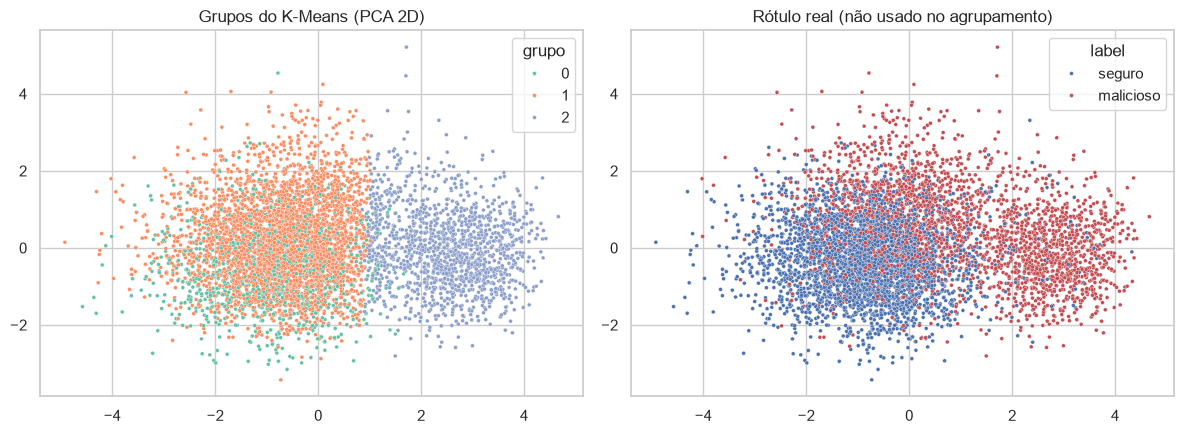

In [5]:
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
df["grupo"] = km.labels_
coords = PCA(n_components=2, random_state=42).fit_transform(X)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["grupo"], palette="Set2", s=8, ax=axes[0])
axes[0].set_title("Grupos do K-Means (PCA 2D)")
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=df["label"].map({0: "seguro", 1: "malicioso"}),
                palette={"seguro": "#4C72B0", "malicioso": "#C44E52"}, s=8, ax=axes[1])
axes[1].set_title("Rótulo real (não usado no agrupamento)")
plt.tight_layout(); plt.savefig(FIGURAS / "agrupamento_pca.png", dpi=120); plt.show()

## 2. Perfil de cada grupo

In [6]:
perfil = df.groupby("grupo")[config.FEATURES].median().T
perfil["média geral"] = df[config.FEATURES].median()
perfil.round(2)

grupo,0,1,2,média geral
log10_tamanho,5.60,5.58,5.21,5.49
num_secoes,6.00,6.00,5.00,6.00
entropia_media_secao,5.38,5.30,6.89,5.60
entropia_max_secao,6.15,6.08,7.73,6.43
num_importacoes,100.00,99.00,22.00,84.00
num_exportacoes,12.00,0.00,0.00,0.00
num_strings,1320.00,1252.00,641.00,1109.50
entropia_strings,5.52,5.56,6.15,5.68
num_urls,2.00,2.00,2.00,2.00
num_paths,3.00,3.00,3.00,3.00


In [7]:
composicao = pd.crosstab(df["grupo"], df["label"].map({0: "seguro", 1: "malicioso"}), normalize="index") * 100
composicao["tamanho do grupo"] = df["grupo"].value_counts().sort_index()
composicao.round(1)

label,malicioso,seguro,tamanho do grupo
grupo,,,
0,22.9,77.1,1085
1,36.2,63.8,3243
2,89.1,10.9,1372


## 3. Interpretação dos grupos

> ⚠️ Valores obtidos com a base **sintética** de demonstração. Refaça a interpretação após rodar com a amostra real do EMBER.

| Grupo | Perfil (medianas) | % maliciosos | Leitura |
|---|---|---|---|
| **2** | entropia ≈ 6,9 (máx ≈ 7,7), ~22 importações, poucas strings, sem assinatura | **≈ 89%** | **Arquivos compactados/ofuscados.** É o perfil clássico de malware empacotado. |
| **0** | ~12 exportações, assinado, entropia normal | ≈ 23% | Bibliotecas (DLLs) e programas assinados: **perfil predominantemente seguro**. |
| **1** | perfil "médio", sem exportações, assinado na maioria | ≈ 36% | **Grupo misto**: aqui estão os malwares "comuns", parecidos com software legítimo. |

**Conclusões:**
- Sem usar o rótulo, o K-Means encontrou um grupo quase todo malicioso, o que **confirma que entropia alta e poucas importações** formam uma assinatura comportamental forte.
- O grupo 1 mistura as classes. É ali que o problema fica difícil, e os modelos supervisionados erram mais nesse grupo (ver análise de erros em 11/11).
- **Uso prático:** o grupo pode virar uma variável de triagem. Arquivos do grupo 2 vão direto para quarentena, e os do grupo 1 dependem do modelo supervisionado.
- **Limitações:** a silhueta é baixa, o K-Means supõe grupos "esféricos" e o resultado depende da padronização. Vale testar também DBSCAN ou agrupamento hierárquico.